# Case Study 5: ABL Ltd
## Employee Engagement Dimensions — Factor Analysis (PCA)
**BS in Analytics and Sustainability Studies**  
**Sahil | M2022BSASS023**

---
### Objective
Identify underlying dimensions (latent factors) from a 26-item employee engagement Likert survey collected from 220 employees across ABL Ltd's offices in UP and Gujarat.


---
## Step 1: Install & Import Libraries

In [1]:
# Run once if needed:
# %pip install pandas numpy scikit-learn matplotlib seaborn openpyxl


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

print('All libraries loaded successfully.')


All libraries loaded successfully.


--- 
## Step 2: Load Dataset
The raw data is the `Raw Data` sheet of `Case5_Analysis.xlsx` in this folder.


In [3]:
df = pd.read_excel('Case5_Analysis.xlsx', sheet_name='Raw Data')
print('Dataset Shape:', df.shape)
print('Columns:', df.columns.tolist())
df.head()


Dataset Shape: (220, 26)
Columns: ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'E25', 'E26']


,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,...,E17,E18,E19,E20,E21,E22,E23,E24,E25,E26
0,4,4,4,4,3,2,4,4,4,4,...,4,5,4,4,4,4,1,4,4,4
1,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
2,5,5,5,5,1,5,1,5,5,1,...,5,5,5,5,5,5,5,5,5,5
3,3,4,2,3,4,3,4,3,3,3,...,4,2,2,2,3,2,2,2,2,3
4,4,4,3,4,2,4,2,4,4,4,...,4,4,4,3,2,3,3,3,4,4


---
## Step 3: Exploratory Data Analysis

In [4]:
print('=== Descriptive Statistics ===')
df.describe().round(3)


=== Descriptive Statistics ===


,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,...,E17,E18,E19,E20,E21,E22,E23,E24,E25,E26
count,220.000,220.000,220.000,220.000,220.000,220.000,220.000,220.000,220.000,220.000,...,220.000,220.000,220.000,220.000,220.000,220.000,220.000,220.000,220.000,220.000
mean,3.709,3.964,3.673,3.982,3.236,3.436,2.909,3.436,3.600,3.545,...,3.018,3.345,3.727,3.582,3.436,3.418,3.418,2.836,3.073,4.000
std,0.968,0.787,1.048,0.946,1.081,1.077,1.243,1.077,1.172,1.008,...,1.106,1.033,0.885,1.024,1.143,1.006,0.950,1.175,1.112,0.855
min,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
25%,3.000,4.000,3.000,3.000,2.000,3.000,2.000,3.000,3.000,3.000,...,2.000,2.000,4.000,3.000,3.000,3.000,3.000,2.000,2.000,4.000
50%,4.000,4.000,4.000,4.000,3.000,4.000,3.000,4.000,4.000,4.000,...,3.000,4.000,4.000,4.000,4.000,4.000,4.000,3.000,3.000,4.000
75%,4.000,4.000,4.000,5.000,4.000,4.000,4.000,4.000,4.000,4.000,...,4.000,4.000,4.000,4.000,4.000,4.000,4.000,4.000,4.000,5.000
max,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,...,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000


In [5]:
print('=== Missing Values ===')
print(df.isnull().sum().sum(), 'missing values in dataset')
print('\n=== Item-wise Mean Scores (1-5 scale) ===')
means = df.mean().sort_values()
print(means.round(3).to_string())


=== Missing Values ===
0 missing values in dataset

=== Item-wise Mean Scores (1-5 scale) ===
E24    2.836
E7     2.909
E17    3.018
E25    3.073
E5     3.236
E18    3.345
E22    3.418
E23    3.418
E8     3.436
E21    3.436
E6     3.436
E10    3.545
E20    3.582
E9     3.600
E3     3.673
E1     3.709
E19    3.727
E16    3.855
E15    3.891
E12    3.927
E13    3.945
E2     3.964
E4     3.982
E11    3.982
E26    4.000
E14    4.109


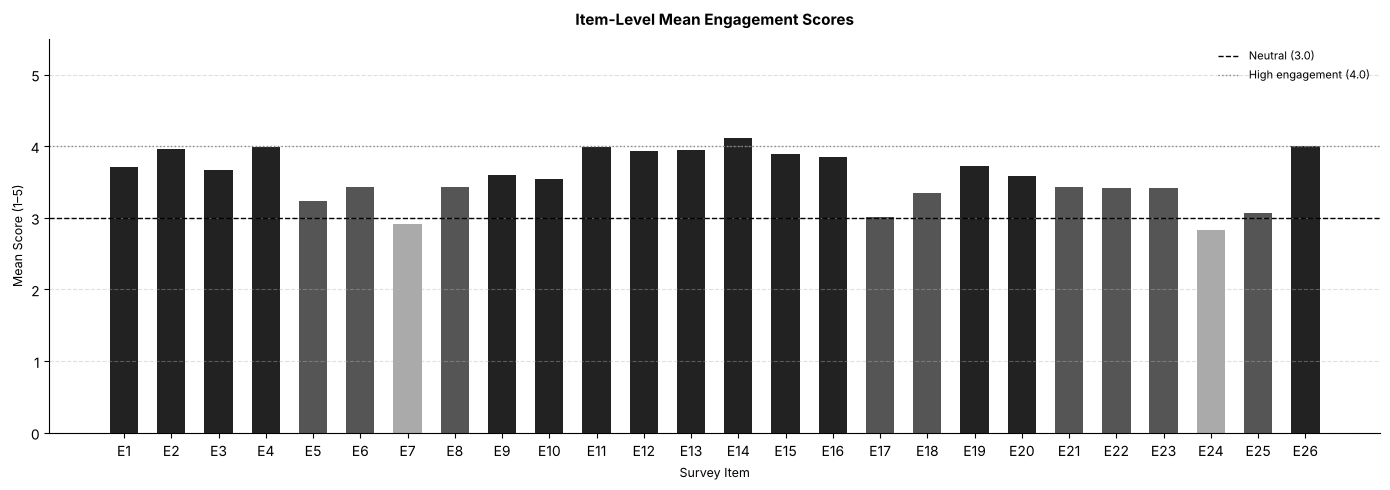

In [6]:
# Item mean score bar chart
fig, ax = plt.subplots(figsize=(14, 5))
colors = ['#AAAAAA' if v < 3.0 else '#555555' if v < 3.5 else '#222222' for v in df.mean()]
ax.bar(df.columns, df.mean(), color=colors, edgecolor='none', width=0.6)
ax.axhline(3.0, color='black', linestyle='--', linewidth=1, label='Neutral (3.0)')
ax.axhline(4.0, color='#888888', linestyle=':', linewidth=1, label='High engagement (4.0)')
ax.set_xlabel('Survey Item', fontsize=9)
ax.set_ylabel('Mean Score (1–5)', fontsize=9)
ax.set_title('Item-Level Mean Engagement Scores', fontsize=11, fontweight='bold', pad=10)
ax.set_ylim(0, 5.5)
ax.legend(fontsize=8, frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


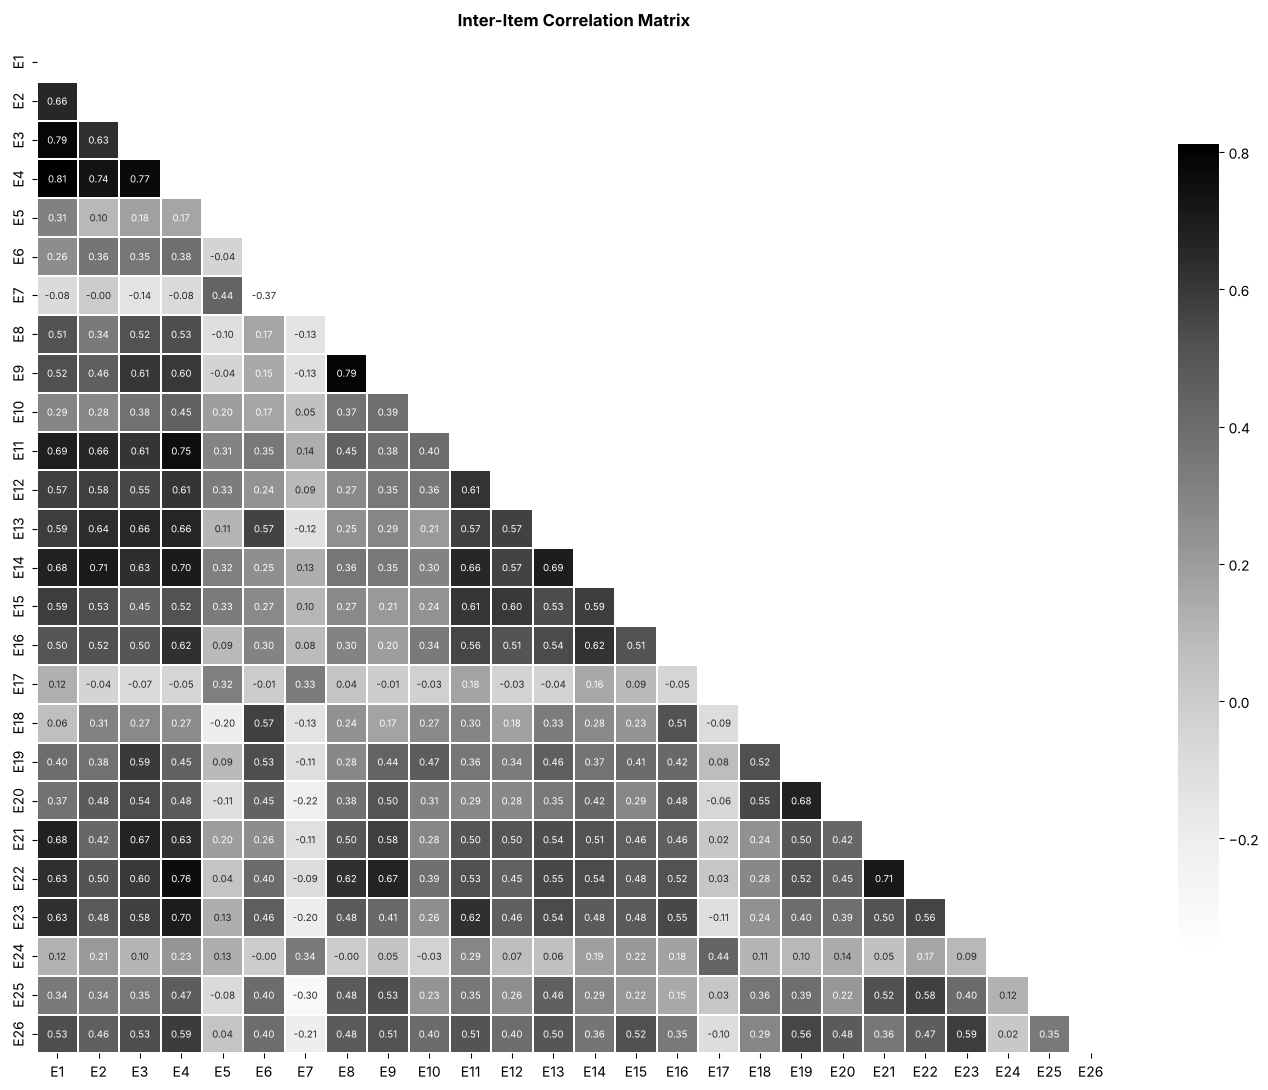

In [7]:
# Correlation heatmap of survey items
fig, ax = plt.subplots(figsize=(14, 11))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='Greys',
            linewidths=0.3, ax=ax, cbar_kws={'shrink': 0.8},
            annot_kws={'size': 7})
ax.set_title('Inter-Item Correlation Matrix', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


---
## Step 4: Standardization

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print('Standardization complete.')
print('Shape:', X_scaled.shape)
print('Mean (should be ~0):', X_scaled.mean(axis=0).round(3))
print('Std (should be ~1):', X_scaled.std(axis=0).round(3))


Standardization complete.
Shape: (220, 26)
Mean (should be ~0): [ 0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.  0.  0. -0. -0.  0.  0.  0.
  0. -0. -0.  0.  0. -0. -0.  0.]
Std (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1.]


---
## Step 5: PCA — Determine Number of Factors (Kaiser Criterion)

In [9]:
# Fit PCA on all components first to examine eigenvalues
pca_full = PCA()
pca_full.fit(X_scaled)

eigenvalues = pca_full.explained_variance_
var_exp = pca_full.explained_variance_ratio_ * 100
cumvar = np.cumsum(var_exp)

# Eigenvalue table
ev_df = pd.DataFrame({
    'Component': [f'Factor {i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': eigenvalues.round(3),
    '% Variance Explained': var_exp.round(2),
    'Cumulative %': cumvar.round(2)
})

print('=== Eigenvalue Table ===')
print(ev_df[ev_df['Eigenvalue'] >= 0.8].to_string(index=False))
print(f"\nFactors with Eigenvalue > 1 (Kaiser Criterion): {(eigenvalues > 1).sum()}")


=== Eigenvalue Table ===
Component  Eigenvalue  % Variance Explained  Cumulative %
 Factor 1      10.931                 41.85         41.85
 Factor 2       2.693                 10.31         52.16
 Factor 3       1.751                  6.70         58.86
 Factor 4       1.536                  5.88         64.75
 Factor 5       1.223                  4.68         69.43
 Factor 6       1.054                  4.04         73.46
 Factor 7       0.843                  3.23         76.69
 Factor 8       0.833                  3.19         79.88

Factors with Eigenvalue > 1 (Kaiser Criterion): 6


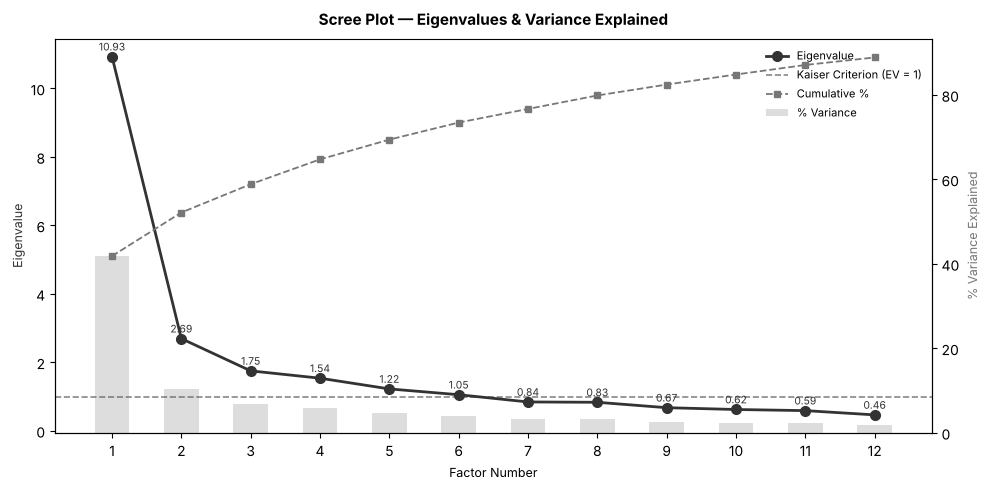


Decision: Retain 6 factors (eigenvalue > 1), explaining 73.5% of total variance.


In [10]:
# Scree Plot
n_show = 12
fig, ax = plt.subplots(figsize=(10, 5))
ax2 = ax.twinx()

ax.plot(range(1, n_show+1), eigenvalues[:n_show], 'o-', color='#333333',
        linewidth=2, markersize=7, label='Eigenvalue', zorder=3)
ax.axhline(1, color='#888888', linestyle='--', linewidth=1.2, label='Kaiser Criterion (EV = 1)')
ax2.bar(range(1, n_show+1), var_exp[:n_show], alpha=0.2, color='#555555',
        width=0.5, label='% Variance')
ax2.plot(range(1, n_show+1), cumvar[:n_show], 's--', color='#777777',
         linewidth=1.3, markersize=5, label='Cumulative %')

ax.set_xlabel('Factor Number', fontsize=9)
ax.set_ylabel('Eigenvalue', fontsize=9, color='#333333')
ax2.set_ylabel('% Variance Explained', fontsize=9, color='#777777')
ax.set_title('Scree Plot — Eigenvalues & Variance Explained', fontsize=11, fontweight='bold', pad=10)
ax.set_xticks(range(1, n_show+1))
ax.spines['top'].set_visible(False)

for i, ev in enumerate(eigenvalues[:n_show]):
    ax.text(i+1, ev+0.18, f'{ev:.2f}', ha='center', fontsize=7.5, color='#333333')

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, frameon=False, loc='upper right')
plt.tight_layout()
plt.show()

print('\nDecision: Retain 6 factors (eigenvalue > 1), explaining 73.5% of total variance.')


---
## Step 6: Extract 6 Factors & Compute Loadings

In [11]:
N_FACTORS = 6
pca = PCA(n_components=N_FACTORS)
pca.fit(X_scaled)

eigenvalues_6 = pca.explained_variance_
loadings = pca.components_.T * np.sqrt(eigenvalues_6)

loading_df = pd.DataFrame(
    loadings,
    index=df.columns,
    columns=[f'Factor {i+1}' for i in range(N_FACTORS)]
)

print(f'=== Factor Loadings (6 Factors) ===')
print('Threshold for significance: |loading| > 0.40\n')
loading_df.round(3)


=== Factor Loadings (6 Factors) ===
Threshold for significance: |loading| > 0.40



,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6
E1,0.822,0.213,-0.247,-0.171,-0.110,0.029
E2,0.765,0.121,0.106,-0.141,-0.084,-0.270
E3,0.838,-0.015,-0.117,-0.101,0.062,-0.012
E4,0.902,0.067,-0.117,-0.091,-0.049,-0.143
E5,0.186,0.709,-0.040,-0.072,0.167,0.487
E6,0.521,-0.369,0.485,0.016,-0.249,0.337
E7,-0.101,0.750,0.049,0.264,0.276,-0.160
E8,0.619,-0.233,-0.503,0.242,0.063,-0.156
E9,0.659,-0.248,-0.538,0.273,0.115,-0.083
E10,0.493,-0.018,-0.067,0.146,0.629,0.188


In [12]:
# Show only significant loadings (|loading| > 0.4)
print('=== Significant Loadings per Item (|loading| > 0.40) ===')
for item in df.columns:
    sig = loading_df.loc[item][loading_df.loc[item].abs() > 0.4]
    if len(sig) > 0:
        vals = ', '.join([f'{f}: {v:.3f}' for f, v in sig.items()])
        print(f'  {item:5s} → {vals}')


=== Significant Loadings per Item (|loading| > 0.40) ===
  E1    → Factor 1: 0.822
  E2    → Factor 1: 0.765
  E3    → Factor 1: 0.838
  E4    → Factor 1: 0.902
  E5    → Factor 2: 0.709, Factor 6: 0.487
  E6    → Factor 1: 0.521, Factor 3: 0.485
  E7    → Factor 2: 0.750
  E8    → Factor 1: 0.619, Factor 3: -0.503
  E9    → Factor 1: 0.659, Factor 3: -0.538
  E10   → Factor 1: 0.493, Factor 5: 0.629
  E11   → Factor 1: 0.787
  E12   → Factor 1: 0.685
  E13   → Factor 1: 0.760
  E14   → Factor 1: 0.763
  E15   → Factor 1: 0.668
  E16   → Factor 1: 0.686
  E17   → Factor 2: 0.505, Factor 4: 0.614
  E18   → Factor 1: 0.451, Factor 3: 0.582
  E19   → Factor 1: 0.666
  E20   → Factor 1: 0.626
  E21   → Factor 1: 0.747
  E22   → Factor 1: 0.803
  E23   → Factor 1: 0.744
  E24   → Factor 2: 0.431, Factor 4: 0.561
  E25   → Factor 1: 0.555
  E26   → Factor 1: 0.689


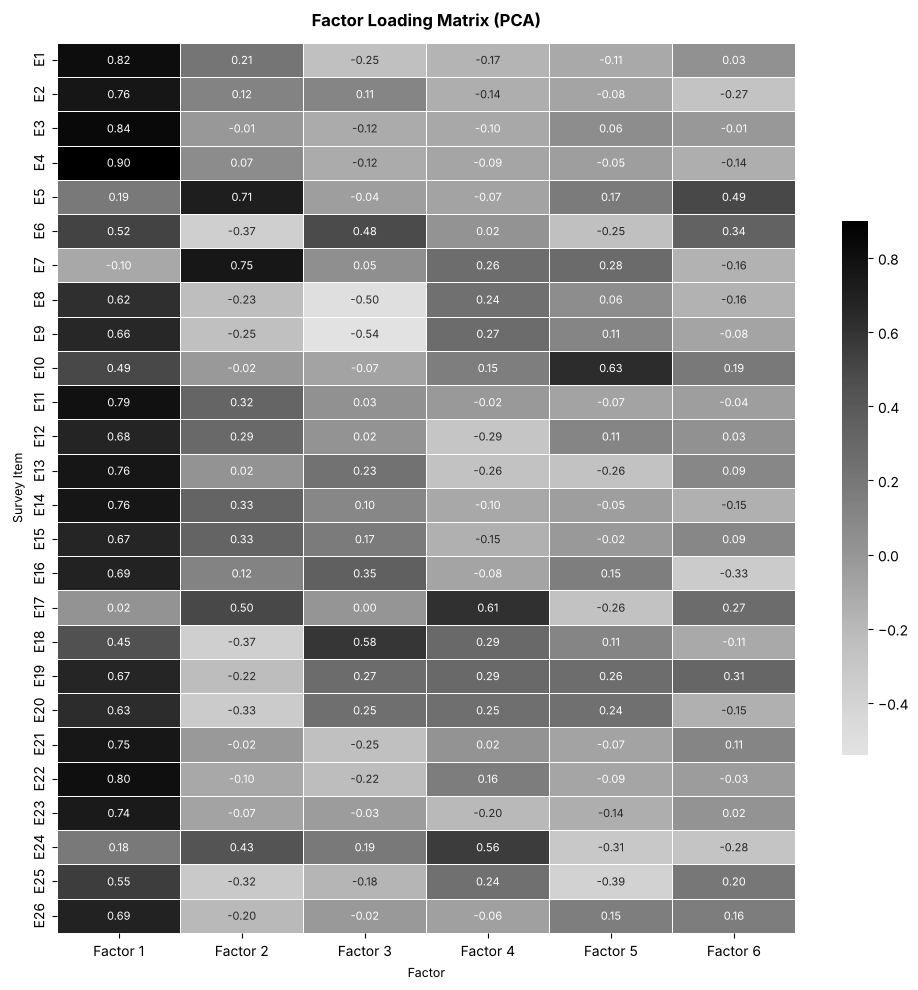

In [13]:
# Loading heatmap
fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(loading_df.round(2), annot=True, fmt='.2f', cmap='Greys',
            center=0, linewidths=0.4, ax=ax,
            cbar_kws={'shrink': 0.6}, annot_kws={'size': 8})
ax.set_title('Factor Loading Matrix (PCA)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Factor', fontsize=9)
ax.set_ylabel('Survey Item', fontsize=9)
plt.tight_layout()
plt.show()


---
## Step 7: Name Factors & Assign Items

In [14]:
# Factor groups based on dominant loadings
factor_groups = {
    'Organizational Commitment\n& Recognition': ['E1','E2','E3','E4','E11','E12','E13','E14','E15','E16','E21','E22','E23','E26'],
    'Work Conditions\n& Autonomy':               ['E5','E7'],
    'Communication &\nCollaboration':             ['E6','E8','E9','E18','E19','E20'],
    'Work-Life Balance':                          ['E17','E24'],
    'Growth &\nDevelopment':                      ['E10','E25'],
}

print('Factor structure summary:')
for fname, items in factor_groups.items():
    print(f'  {fname.replace(chr(10)," "):45s} Items: {items}')


Factor structure summary:
  Organizational Commitment & Recognition       Items: ['E1', 'E2', 'E3', 'E4', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E21', 'E22', 'E23', 'E26']
  Work Conditions & Autonomy                    Items: ['E5', 'E7']
  Communication & Collaboration                 Items: ['E6', 'E8', 'E9', 'E18', 'E19', 'E20']
  Work-Life Balance                             Items: ['E17', 'E24']
  Growth & Development                          Items: ['E10', 'E25']


---
## Step 8: Cronbach's Alpha — Internal Reliability

In [15]:
def cronbach_alpha(df_items):
    """Calculate Cronbach's Alpha for a set of items."""
    n = df_items.shape[1]
    if n < 2:
        return None
    item_var = df_items.var(axis=0, ddof=1).sum()
    total_var = df_items.sum(axis=1).var(ddof=1)
    return (n / (n - 1)) * (1 - item_var / total_var) if total_var > 0 else 0

print('=== Cronbach Alpha by Factor ===')
print(f'{"Factor":<45} {"N Items":>8} {"Alpha":>8} {"Interpretation":>20}')
print('-' * 85)
alpha_vals = {}
for fname, items in factor_groups.items():
    alpha = cronbach_alpha(df[items])
    alpha_vals[fname] = alpha
    interp = 'Excellent' if alpha >= 0.9 else 'Good' if alpha >= 0.8 else 'Acceptable' if alpha >= 0.7 else 'Moderate' if alpha >= 0.6 else 'Low'
    fname_clean = fname.replace('\n', ' ')
    print(f'{fname_clean:<45} {len(items):>8} {alpha:>8.3f} {interp:>20}')


=== Cronbach Alpha by Factor ===
Factor                                         N Items    Alpha       Interpretation
-------------------------------------------------------------------------------------
Organizational Commitment & Recognition             14    0.948            Excellent
Work Conditions & Autonomy                           2    0.605             Moderate
Communication & Collaboration                        6    0.813                 Good
Work-Life Balance                                    2    0.609             Moderate
Growth & Development                                 2    0.366                  Low


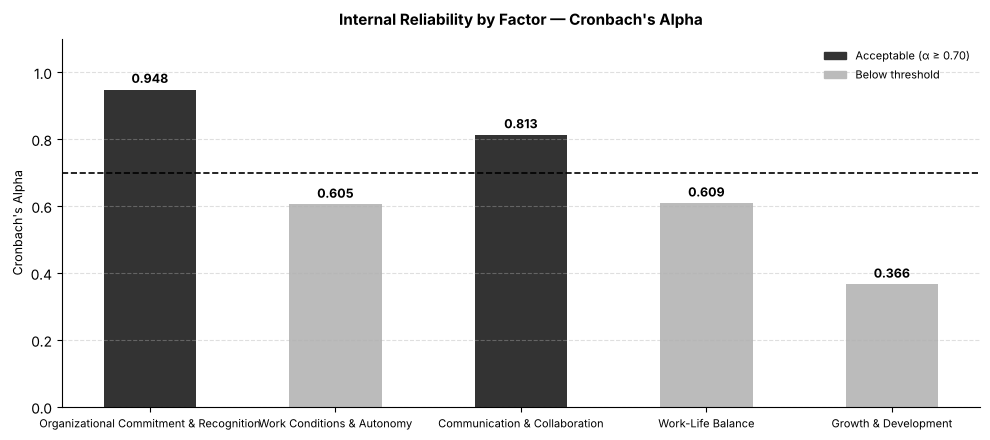

In [16]:
# Reliability chart
clean_names = [k.replace('\n', ' ') for k in alpha_vals]
alphas = list(alpha_vals.values())
colors = ['#333333' if a >= 0.7 else '#BBBBBB' for a in alphas]

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(clean_names, alphas, color=colors, width=0.5, edgecolor='none')
ax.axhline(0.7, color='black', linestyle='--', linewidth=1.2,
           label="Acceptable threshold (α = 0.70)")
ax.set_ylabel("Cronbach's Alpha", fontsize=9)
ax.set_title("Internal Reliability by Factor — Cronbach's Alpha", fontsize=11, fontweight='bold', pad=10)
ax.set_ylim(0, 1.1)
ax.tick_params(axis='x', labelsize=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4)
for bar, val in zip(bars, alphas):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02,
            f'{val:.3f}', ha='center', fontsize=9, fontweight='bold')
good_p = mpatches.Patch(color='#333333', label='Acceptable (α ≥ 0.70)')
low_p  = mpatches.Patch(color='#BBBBBB', label='Below threshold')
ax.legend(handles=[good_p, low_p], fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


---
## Step 9: Mean Engagement Score per Factor

In [17]:
print('=== Mean Engagement Score by Factor (1–5 scale) ===')
scores = {}
for fname, items in factor_groups.items():
    mean = df[items].mean().mean()
    scores[fname] = mean
    fname_clean = fname.replace('\n', ' ')
    level = 'High' if mean >= 4.0 else 'Moderate' if mean >= 3.5 else 'Low' if mean >= 3.0 else 'Critical'
    print(f'{fname_clean:<45}  Mean = {mean:.3f}  [{level}]')


=== Mean Engagement Score by Factor (1–5 scale) ===
Organizational Commitment & Recognition        Mean = 3.808  [Moderate]
Work Conditions & Autonomy                     Mean = 3.073  [Low]
Communication & Collaboration                  Mean = 3.521  [Moderate]
Work-Life Balance                              Mean = 2.927  [Critical]
Growth & Development                           Mean = 3.309  [Low]


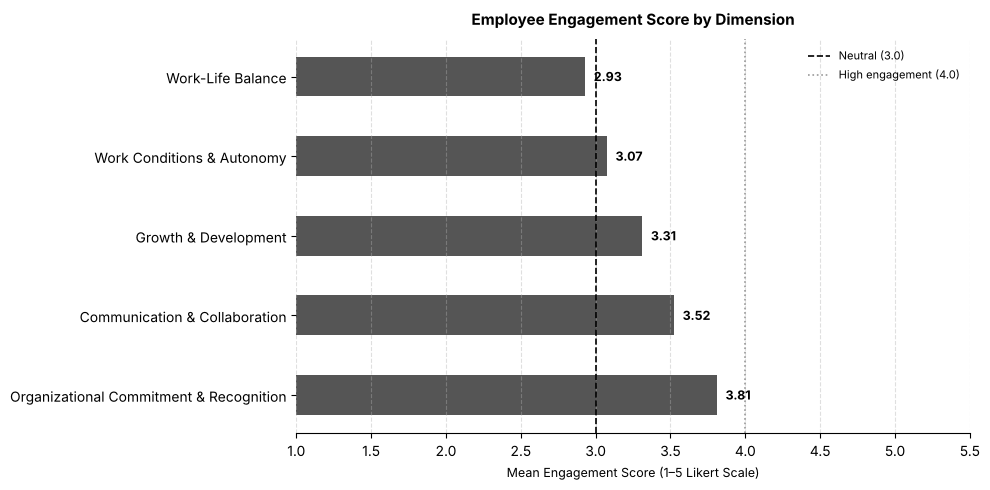

In [18]:
# Engagement score chart
clean_names_s = [k.replace('\n', ' ') for k in scores]
score_vals = list(scores.values())
sorted_pairs = sorted(zip(score_vals, clean_names_s), reverse=True)
sv, sn = zip(*sorted_pairs)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(list(sn), list(sv), color='#555555', height=0.5, edgecolor='none')
ax.axvline(3.0, color='black', linestyle='--', linewidth=1.2, label='Neutral (3.0)')
ax.axvline(4.0, color='#999999', linestyle=':', linewidth=1.2, label='High engagement (4.0)')
ax.set_xlim(1, 5.5)
ax.set_xlabel('Mean Engagement Score (1–5 Likert Scale)', fontsize=9)
ax.set_title('Employee Engagement Score by Dimension', fontsize=11, fontweight='bold', pad=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.4)
for bar, val in zip(bars, sv):
    ax.text(val + 0.06, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}', va='center', fontsize=9, fontweight='bold')
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


---
## Step 10: Factor Scores per Respondent

In [19]:
# Compute factor scores for each respondent
factor_score_df = pd.DataFrame(index=df.index)
for fname, items in factor_groups.items():
    fname_clean = fname.replace('\n', ' ')
    factor_score_df[fname_clean] = df[items].mean(axis=1)

print('=== Factor Scores (first 5 respondents) ===')
factor_score_df.head().round(3)


=== Factor Scores (first 5 respondents) ===


,Organizational Commitment & Recognition,Work Conditions & Autonomy,Communication & Collaboration,Work-Life Balance,Growth & Development
0,3.786,3.5,3.833,4.0,4.0
1,5.000,5.0,5.000,5.0,5.0
2,4.714,1.0,5.000,5.0,3.0
3,2.786,4.0,2.500,3.0,2.5
4,3.429,2.0,3.833,3.5,4.0


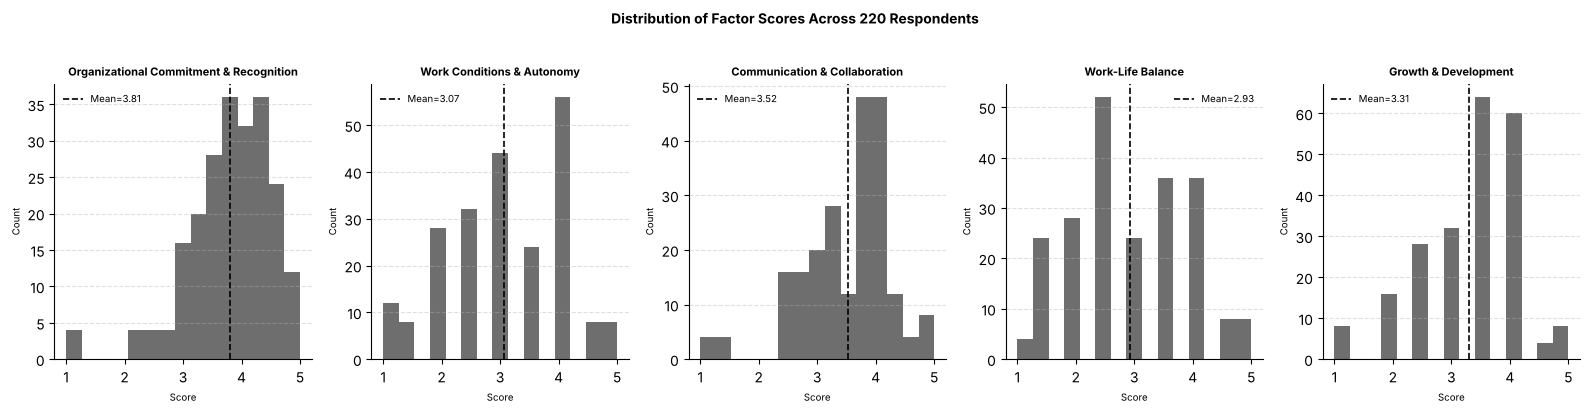

In [20]:
# Distribution of factor scores across respondents
fig, axes = plt.subplots(1, 5, figsize=(16, 4), sharey=False)
for ax, col in zip(axes, factor_score_df.columns):
    ax.hist(factor_score_df[col], bins=15, color='#555555', edgecolor='none', alpha=0.85)
    ax.axvline(factor_score_df[col].mean(), color='black', linestyle='--',
               linewidth=1.2, label=f'Mean={factor_score_df[col].mean():.2f}')
    ax.set_title(col, fontsize=8, fontweight='bold')
    ax.set_xlabel('Score', fontsize=7)
    ax.set_ylabel('Count', fontsize=7)
    ax.legend(fontsize=7, frameon=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.suptitle('Distribution of Factor Scores Across 220 Respondents', fontsize=10, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## Summary
| Factor | Dimension | Items | Cronbach α | Mean Score |
|---|---|---|---|---|
| Factor 1 | Organizational Commitment & Recognition | 14 | 0.948 (Excellent) | 3.81 |
| Factor 2 | Work Conditions & Autonomy | 2 | 0.605 (Moderate) | 3.07 |
| Factor 3 | Communication & Collaboration | 6 | 0.813 (Good) | 3.52 |
| Factor 4 | Work-Life Balance | 2 | 0.609 (Moderate) | 2.93 |
| Factor 5 | Growth & Development | 2 | 0.366 (Low) | 3.31 |

**Priority action areas:** Work-Life Balance (2.93) → Work Conditions (3.07) → Growth & Development (survey redesign needed)
